# Songs 1970–1975: clusters by lyrics, instruments and country

**Research question.** To what extent can songs from 1970–1975 be grouped into meaningful clusters based on lyrical themes, country of origin and instrumentation, and how do these clusters correspond to established musical genres?

1. Clustering: do the song graphs have genuine community structure?
2. Associations between instrument, theme and country.
3. Alignment of the clusters with genre.

This notebook runs the whole analysis in order; the functions live in `src/`. The data decisions (genre labels, country, instrument families, which songs enter which graph) are explained in `Documentation.ipynb`. All randomness is driven by `SEED`. Figures go to `figures/` (PDF + PNG), tables to `results/`.

In [1]:
import os
# must be set before numpy is imported: works around a broken MKL OpenMP layer in our
# conda environment (see src/__init__.py); no effect without MKL
os.environ.setdefault("MKL_THREADING_LAYER", "TBB")

import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import networkx as nx

from src.config import SEED, FIG_DIR, RESULTS_DIR
from src.dataset import load_analysis_songs
from src import graphs, backbone as bb, plotting

FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
ALPHA = 0.05   # disparity-filter significance level (Step 6C varies it)
plotting.use_style()
print("SEED =", SEED, "| ALPHA =", ALPHA)

SEED = 42 | ALPHA = 0.05


## Data

One row per song first released 1970–1975 (MusicBrainz), with Genius lyrics where matched. Songs whose lyrics are a near-copy of another song by the same artist are dropped as duplicates (spelling variants the title matching missed). Covers by other artists are kept.

Filler words are removed from the tokens when `config.REMOVE_FILLER_WORDS` is True. These are vocables like "ooh", "la" and "yeah", plus what spaCy leaves of contractions, like "gon" + "na" from "gonna" (lists in `src/text.py`). They make up about 10% of the tokens, and they would otherwise be among the most common top-10 words. Set the flag to False to undo it.

`genre_eval` is the evaluation genre: the vote-based coarse genre, with classes under 30 songs merged into "other". **Genre is only metadata: it is never used to build an edge.**

In [2]:
songs = load_analysis_songs()
lyr = songs[songs.has_lyrics]

coverage = pd.Series({
    "songs": len(songs),
    "with lyrics": songs.has_lyrics.sum(),
    "with instruments": songs.has_instruments.sum(),
    "with lyrics and instruments": (songs.has_lyrics & songs.has_instruments).sum(),
}, name="n")
display(coverage.to_frame())
display(lyr.genre_eval.value_counts(dropna=False).rename("songs with lyrics").to_frame())

Filler words removed: 10.5% of the lyrics tokens (config.REMOVE_FILLER_WORDS)


11032 songs 1970-1975 (7 lyric duplicates dropped): 3227 with lyrics, 735 with instruments, 519 with both


,n
songs,11032
with lyrics,3227
with instruments,735
with lyrics and instruments,519


,songs with lyrics
genre_eval,
rock,1567
rb,571
country,331
pop,325
NaN,234
folk,85
other,73
reggae,41


## Step 1 — Three song graphs

| Graph | Songs | Edges |
|---|---|---|
| `G_lyrics` | all songs with lyrics | cosine similarity of TF-IDF vectors |
| `G_instruments` | all songs with instrument data | hyperbolic projection of song–instrument family |
| `G_combined` | songs with lyrics, instruments and country | hyperbolic projection of song–(instrument family, country, top-10 words) |

There is no country-only graph: projecting song–country would just give one clique per country. Country is used as metadata (like genre) and as a feature inside `G_combined`.

### G_lyrics

TF-IDF on the spaCy tokens (used as they are), with `min_df=2` (a word must occur in two songs to link them), `max_df=0.5` (words in more than half the songs are near-stop words) and `sublinear_tf=True` (tf = 1 + ln count, so a repeated chorus word cannot dominate). Rows are L2-normalised, so their dot product is the cosine similarity.

Almost every pair of songs shares some word, so the full similarity graph is 89% complete (≈4.6M edges). That is too dense for networkx, but small as a dense 3,227 × 3,227 matrix. So `G_lyrics` is kept as the matrix `S` and only becomes a networkx graph after the disparity filter (Step 2).

We first tried keeping only each song's 20 most similar songs, but then the disparity filter kept just 95 edges. A song's 20 nearest neighbours all have similar weights, so none of them stands out against the others; the weak edges the filter needs as contrast are exactly the ones a top-k cut removes.

In [3]:
X, terms = graphs.tfidf(lyr.tokens)
S_lyrics = graphs.lyrics_similarity(X)      # G_lyrics as a dense weight matrix
lyrics_ids = lyr.index.to_numpy()
print(f"TF-IDF vocabulary: {len(terms)} words")
graphs.dense_summary(S_lyrics)

TF-IDF vocabulary: 6942 words


{'nodes': 3227,
 'edges': 4648311,
 'density': 0.8930213551921933,
 'components': 2,
 'isolated': 1,
 'lcc_nodes': 3226,
 'lcc_share': np.float64(0.9996901146575767)}

### G_instruments

Bipartite graph of songs and instrument families (`bipartite=0/1`), projected onto the songs with Newman's hyperbolic weighting (`collaboration_weighted_projected_graph`). A family shared by *k* songs adds 1/(*k*−1) to each of their pairs. So guitar, bass and drums, which are on 80–85% of the songs, add very little to any single pair, while a rare shared family (harmonica, folk strings) adds a lot. The projection is still almost complete, because nearly every pair shares guitar, bass or drums. The disparity filter will remove those weak links.

In [4]:
B_instruments = graphs.bipartite_graph(graphs.instrument_features(songs))
G_instruments = graphs.add_metadata(graphs.project(B_instruments), songs)
graphs.summary(G_instruments)

{'nodes': 735,
 'edges': 247574,
 'density': 0.9178075589908988,
 'components': 1,
 'isolated': 0,
 'lcc_nodes': 735,
 'lcc_share': 1.0}

### G_combined

Songs link to three kinds of feature nodes: `inst:<family>`, `country:<release country>` and `word:<w>` for the song's 10 highest-TF-IDF words. The words are the lyrical themes, taken from the same TF-IDF as `G_lyrics`, so the IDF is estimated on all songs with lyrics.

**Balanced projection.** Each feature type gets its own bipartite graph and hyperbolic projection. Each projection's weights are scaled to sum to 1, and the three are added edge by edge (`graphs.balanced_projection`), so instruments, country and words count equally in total.

We first projected all features in one bipartite graph. A feature of degree *k* gives each of its pairs 1/(*k*−1): a word shared by just two songs gives weight 1, while "guitar" (≈600 songs) gives 0.002. The disparity filter then kept almost only word edges, and words carried 94% of the backbone's weight, so `G_combined` was in effect a lyrics graph. The table shows the shares in that single projection, for comparison.

In [5]:
words = dict(zip(lyr.index, graphs.top_words(X, terms)))
combined_feats = graphs.combined_features(songs, words)
G_combined = graphs.add_metadata(graphs.balanced_projection(combined_feats), songs)

B_combined = graphs.bipartite_graph(combined_feats)   # single projection, for comparison only
display(pd.DataFrame({"single projection": graphs.feature_weight_shares(B_combined),
                      "balanced (used)": graphs.type_shares(G_combined)}).round(3))
feature_nodes = [n for n, b in B_combined.nodes(data="bipartite") if b == 1]
print(f"{len(feature_nodes)} feature nodes, {sum(B_combined.degree(f) == 1 for f in feature_nodes)} "
      "of them on a single song (they link nobody)")
graphs.summary(G_combined)

,single projection,balanced (used)
word,0.556,0.333
inst,0.360,0.333
country,0.084,0.333


2867 feature nodes, 1808 of them on a single song (they link nobody)


{'nodes': 519,
 'edges': 126286,
 'density': 0.9394811822557487,
 'components': 1,
 'isolated': 0,
 'lcc_nodes': 519,
 'lcc_share': 1.0}

In [6]:
from collections import Counter
print("Most common top-10 words over the songs with lyrics:")
print(Counter(w for ws in words.values() for w in ws).most_common(25))

Most common top-10 words over the songs with lyrics:
[('baby', 203), ('love', 137), ('wanna', 97), ('girl', 81), ('woman', 79), ('want', 78), ('let', 77), ('need', 76), ('come', 72), ('yes', 70), ('life', 70), ('tell', 68), ('rock', 67), ('lord', 63), ('sweet', 63), ('little', 62), ('going', 62), ('home', 61), ('feel', 61), ('man', 60), ('sing', 60), ('mama', 59), ('everybody', 59), ('roll', 59), ('good', 59)]


In [7]:
step1 = pd.DataFrame({"G_lyrics": graphs.dense_summary(S_lyrics),
                      "G_instruments": graphs.summary(G_instruments),
                      "G_combined": graphs.summary(G_combined)}).T
step1["avg_degree"] = 2 * step1.edges / step1.nodes
step1.to_csv(RESULTS_DIR / "step1_graphs.csv")
step1.round(4)

,nodes,edges,density,components,isolated,lcc_nodes,lcc_share,avg_degree
G_lyrics,3227.0,4648311.0,0.8930,2.0,1.0,3226.0,0.9997,2880.8869
G_instruments,735.0,247574.0,0.9178,1.0,0.0,735.0,1.0000,673.6707
G_combined,519.0,126286.0,0.9395,1.0,0.0,519.0,1.0000,486.6513


## Step 2 — Backbones with the disparity filter

The graphs are dense (the projections are more than 90% complete) and their edge weights are broadly distributed (figure below). A global weight threshold would keep every edge of the strong songs and none of the weak ones. The disparity filter (Serrano, Boguñá & Vespignani 2009) tests each edge against its own endpoints instead. Seen from song *u*, with strength *s_u* and degree *k_u*,

$$p_u(u,v) = \left(1 - \frac{w_{uv}}{s_u}\right)^{k_u - 1}$$

is the probability that a uniformly random split of *u*'s strength over its *k_u* edges gives one edge at least *w_uv*. The edge is kept if *p* < α from **either** endpoint, so it is enough that it matters to one of the two songs. The single edge of a degree-1 song is always kept. We use α = 0.05 (Step 6C repeats everything with 0.01 and 0.1). Our implementation (`src/backbone.py`) matches a direct edge-by-edge loop over the formula on 200-song test graphs, at all three α values.

### Edge weights before backboning

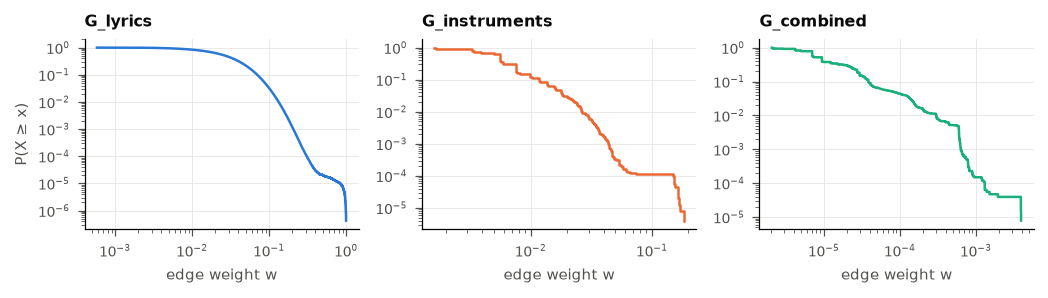

In [8]:
weights = {"G_lyrics": graphs.upper_weights(S_lyrics),
           "G_instruments": [w for *_, w in G_instruments.edges(data="weight")],
           "G_combined": [w for *_, w in G_combined.edges(data="weight")]}
fig = plotting.ccdf_panels(weights, "edge weight w", name="edge_weight_ccdf")

### Backbones

The p-values are computed once per graph. `backbone(P, alpha)` is then just a threshold, which makes the α sensitivity check in Step 6C cheap. `G_lyrics` is filtered on its dense matrix (`disparity_pvalues_dense`), which gives the same p-values as the graph version (tested in `src/backbone.py`). Community detection uses each backbone's largest connected component (LCC).

In [9]:
P = {"G_lyrics": graphs.add_metadata(bb.disparity_pvalues_dense(S_lyrics, lyrics_ids, keep_below=0.1), songs),
     "G_instruments": bb.disparity_pvalues(G_instruments),
     "G_combined": bb.disparity_pvalues(G_combined)}
before = {"G_lyrics": graphs.dense_summary(S_lyrics),
          "G_instruments": graphs.summary(G_instruments),
          "G_combined": graphs.summary(G_combined)}

backbones, lcc, rows = {}, {}, []
for name, Pg in P.items():
    backbones[name] = bb.backbone(Pg, ALPHA)
    lcc[name] = bb.largest_component(backbones[name])
    b, a = before[name], graphs.summary(backbones[name])
    rows.append({"graph": name, "nodes": b["nodes"],
                 "edges_before": b["edges"], "edges_after": a["edges"], "edges_kept": a["edges"] / b["edges"],
                 "density_before": b["density"], "density_after": a["density"],
                 "components_before": b["components"], "components_after": a["components"],
                 "isolated_after": a["isolated"], "lcc_nodes": lcc[name].number_of_nodes(),
                 "songs_dropped": b["nodes"] - lcc[name].number_of_nodes(),
                 "lcc_edges": lcc[name].number_of_edges()})
step2 = pd.DataFrame(rows).set_index("graph")
step2.to_csv(RESULTS_DIR / "step2_backbone.csv")
step2.T.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

graph,G_lyrics,G_instruments,G_combined
nodes,"3,227",735,519
edges_before,4.648e+06,2.476e+05,1.263e+05
edges_after,1.618e+05,"6,706","6,835"
edges_kept,0.03482,0.02709,0.05412
density_before,0.893,0.9178,0.9395
density_after,0.03109,0.02486,0.05085
components_before,2,1,1
components_after,2,437,1
isolated_after,1,436,0
lcc_nodes,"3,226",299,519


### What the instrument backbone drops

In `G_instruments`, a song whose instrument families are all common (e.g. bass + drums + guitar) has nearly equal weights to every other song. None of its edges stands out, so the filter removes them all, and 436 of the 735 songs end up isolated. We keep the families and treat this as a result: a standard rock line-up carries no distinguishing instrument information.

With the original instrument names the LCC would have 500 songs, but part of what separates them is just how the credits are written ("bass" vs "bass guitar"). The table shows the most common family sets and the share of their songs in the LCC.

In [10]:
inst = songs[songs.has_instruments].assign(in_lcc=lambda d: d.index.isin(lcc["G_instruments"].nodes))
(inst.groupby("instrument_families").in_lcc.agg(songs="size", share_in_lcc="mean")
     .sort_values("songs", ascending=False).head(12).round(2))

,songs,share_in_lcc
instrument_families,,
bass;drums;guitar,82,0.0
bass;drums;guitar;keys,71,0.0
bass;drums;guitar;keys;percussion,40,0.0
keys,30,0.0
bass;drums;guitar;organ,28,0.0
bass;drums;guitar;percussion,26,0.0
guitar,22,0.0
bass;drums;guitar;keys;organ,21,0.0
bass;folk strings;guitar,12,1.0


### Which features hold G_combined's backbone together

Every edge stores its weight from each feature type. The types have equal shares before the filter, by construction. After the filter, the shares show which types produce edges that stand out for their songs.

In [11]:
pd.DataFrame({"before backbone": graphs.type_shares(G_combined),
              "backbone LCC": graphs.type_shares(lcc["G_combined"])}).round(3)

,before backbone,backbone LCC
inst,0.333,0.041
country,0.333,0.289
word,0.333,0.670


## Step 3 — Descriptive statistics of the backbones

The statistics describe the graphs communities will be found in: each backbone (α = 0.05) and its largest connected component (LCC). The unfiltered projections are almost complete graphs, so their degrees and clustering say little.

- **Degree distribution.** A CCDF on log-log axes, P(K ≥ k), which needs no binning. We only describe its shape and don't fit a power law.
- **Clustering.** The average local clustering coefficient, unweighted (as in the course) and weighted (Onnela's geometric-mean version, `nx.average_clustering(weight=...)`). It is compared with two random baselines:
  - an Erdős–Rényi graph of the same density, where *C* = density;
  - the configuration model with the same degrees, where *C* = (⟨k²⟩ − ⟨k⟩)² / (⟨k⟩³ *N*).

  If *C* is well above both, songs form more triangles than their degrees alone would produce, i.e. there are local groups of mutually similar songs.

In [12]:
rows = {}
for name in backbones:
    full, d = graphs.summary(backbones[name]), graphs.degree_stats(lcc[name])
    rows[name] = {"backbone_nodes": full["nodes"], "backbone_edges": full["edges"],
                  "components": full["components"], "isolated": full["isolated"],
                  "lcc_nodes": d["nodes"], "lcc_share": d["nodes"] / full["nodes"], "lcc_edges": d["edges"],
                  "avg_degree": d["avg_degree"], "median_degree": d["median_degree"], "max_degree": d["max_degree"],
                  "avg_clustering": d["avg_clustering"], "avg_clustering_weighted": d["avg_clustering_weighted"],
                  "C_rand (ER)": d["C_rand"], "C_conf (config.)": d["C_conf"],
                  "C / C_conf": d["avg_clustering"] / d["C_conf"]}
step3 = pd.DataFrame(rows)
step3.T.to_csv(RESULTS_DIR / "step3_descriptive.csv")
step3.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

,G_lyrics,G_instruments,G_combined
backbone_nodes,"3,227",735,519
backbone_edges,1.618e+05,"6,706","6,835"
components,2,437,1
isolated,1,436,0
lcc_nodes,"3,226",299,519
lcc_share,0.9997,0.4068,1
lcc_edges,1.618e+05,"6,706","6,835"
avg_degree,100.3,44.86,26.34
median_degree,91,48,23
max_degree,475,111,68


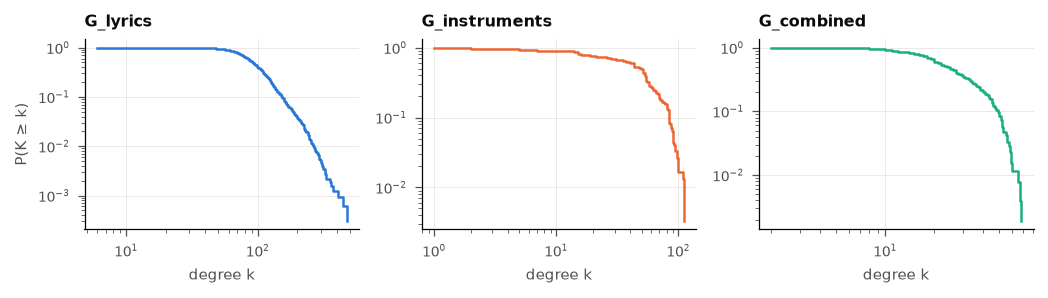

In [13]:
degrees = {name: [d for _, d in g.degree()] for name, g in lcc.items()}
fig = plotting.ccdf_panels(degrees, "degree k", name="degree_ccdf", ylabel="P(K ≥ k)")

## Step 4 — Louvain communities

Louvain (`nx.community.louvain_communities(G, weight="weight", seed=SEED)`) maximises the weighted modularity

$$M = \frac{1}{2W}\sum_{ij}\left(w_{ij} - \frac{s_i s_j}{2W}\right)\delta(c_i, c_j),$$

the share of edge weight inside communities minus what is expected if the same node strengths *s* were wired at random. It runs on each backbone's LCC. Communities are numbered by size (0 = largest) and stored on the nodes as `community`. Louvain is randomised, so Step 6C repeats it with 20 seeds.

Modularity has a resolution limit: groups smaller than about √(2W) cannot be resolved, so small genres may be merged into bigger communities. Communities with fewer than 10 songs are counted, but not described in Step 6D. Louvain's result also depends on the order in which nodes are stored, not only on the seed. Within this notebook that order is fixed, so the results are reproducible.

In [14]:
from src import communities as cm

partitions, rows = {}, {}
for name, g in lcc.items():
    comms, M = cm.detect(g, seed=SEED)
    partitions[name] = comms
    rows[name] = {"nodes": g.number_of_nodes(), "edges": g.number_of_edges(), "M": M,
                  **cm.size_summary(comms)}
step4 = pd.DataFrame(rows)
step4.T.to_csv(RESULTS_DIR / "step4_communities.csv")

# one row per song and graph, so the partitions can be reused without re-running Louvain
pd.concat([pd.DataFrame({"graph": name, "song_id": list(cm.membership(c)), "community": list(cm.membership(c).values())})
           for name, c in partitions.items()]).to_csv(RESULTS_DIR / "step4_partitions.csv", index=False)
step4.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

,G_lyrics,G_instruments,G_combined
nodes,"3,226",299,519
edges,1.618e+05,"6,706","6,835"
M,0.2261,0.484,0.4065
communities,10,6,15
communities_ge10,10,5,15
share_in_ge10,1,0.9732,1
largest,629,85,59
largest_share,0.195,0.2843,0.1137
median_size,308.5,45.5,31
singletons,0,0,0


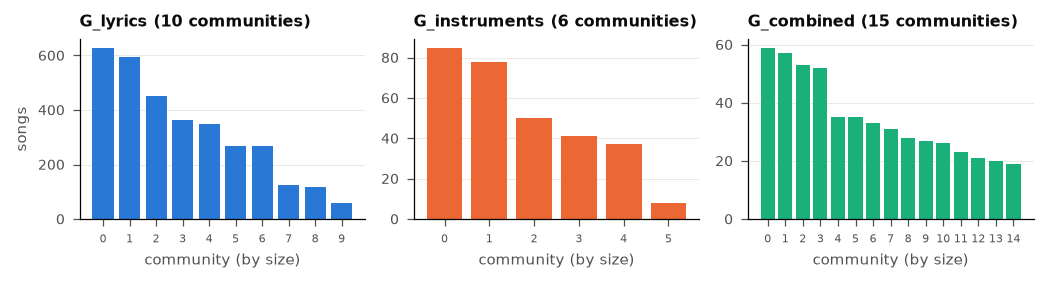

In [15]:
fig = plotting.size_panels({name: [len(c) for c in comms] for name, comms in partitions.items()},
                           name="community_sizes")

A first look at what the communities contain: the share of each evaluation genre per community (rows sum to 100%; songs without a genre left out). Step 5 measures the agreement properly (AMI, ARI, assortativity, heatmaps) for genre and country.

In [16]:
for name, g in lcc.items():
    print(name)
    display(cm.composition(g, "genre_eval").round(0).astype(int))

G_lyrics


label,country,folk,other,pop,rb,reggae,rock
community,,,,,,,
0,13,5,2,13,11,1,56
1,12,3,2,11,11,2,59
2,5,0,3,9,39,1,42
3,14,3,3,7,17,2,54
4,5,3,1,10,22,1,60
5,10,5,6,15,22,1,42
6,14,2,2,8,21,2,52
7,17,3,2,13,27,1,38
8,18,1,2,17,12,1,50


G_instruments


label,country,folk,other,pop,rb,rock
community,,,,,,
0,34,4,0,2,6,54
1,0,0,0,11,4,85
2,2,0,24,6,22,46
3,18,8,0,0,3,71
4,24,0,0,15,3,59


G_combined


label,country,folk,other,pop,rb,reggae,rock
community,,,,,,,
0,22,5,0,8,2,0,63
1,2,0,0,11,5,0,82
2,2,4,0,10,8,0,77
3,0,4,0,6,10,0,80
4,6,0,0,29,6,0,60
5,6,0,0,6,12,0,76
6,3,0,0,16,16,0,66
7,0,3,0,0,0,0,97
8,0,0,0,0,4,0,96
